# Crop Classification — PASTIS Subset

Geo Data Scientist Assignment. Sections follow the assignment order, Task A (data loading) through Task G (analysis and interpretation), with the items inside each task in the order they are listed in the brief.

## Task A: Data Loading and Preparation

### Imports
All imports used across this notebook, gathered in one place so the environment requirements are visible up front (see `requirements.txt`).

In [35]:
# --- Standard library ---
from pathlib import Path
import os
import re
import json
import time
import gc

# --- Data handling and plotting ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import shape

# --- Modelling and evaluation ---
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    jaccard_score,
    matthews_corrcoef,
    precision_recall_fscore_support,
)

### Set paths and confirm the data exists
All paths are relative to the project root, so the notebook runs unchanged on another machine. Place the data at `data/PASTIS_subset/` (with `DATA_S2/`, `ANNOTATIONS/` and `metadata.geojson` inside), or point the `PASTIS_DATA_DIR` environment variable to wherever it is stored.

In [2]:
# --- Paths (relative to the project root, so the notebook runs on any machine) ---
# The notebook lives in <project-root>/notebooks/. If it is run from there, the project
# root is the parent folder; if it is run from the project root itself, it is the cwd.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Data folder: <project-root>/data/PASTIS_subset by default.
# To keep the data elsewhere, set the PASTIS_DATA_DIR environment variable instead.
BASE_DIR = Path(os.environ.get("PASTIS_DATA_DIR", PROJECT_ROOT / "data" / "PASTIS_subset"))
S2_DIR   = BASE_DIR / "DATA_S2"
ANN_DIR  = BASE_DIR / "ANNOTATIONS"
META_FP  = BASE_DIR / "metadata.geojson"

# Output folders (created if missing), matching the repository structure
OUT_DIR     = PROJECT_ROOT / "outputs"
FIG_DIR     = OUT_DIR / "figures"
METRICS_DIR = OUT_DIR / "metrics"
PRED_DIR    = OUT_DIR / "predictions"
MODEL_DIR   = OUT_DIR / "models"        # excluded from git (model is ~765 MB)
SPLIT_DIR   = PROJECT_ROOT / "splits"   # patch-ID text files for each split
for d in [FIG_DIR, METRICS_DIR, PRED_DIR, MODEL_DIR, SPLIT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# --- Check that the input data exists before going further ---
for p in [BASE_DIR, S2_DIR, ANN_DIR, META_FP]:
    print(f"{'OK     ' if p.exists() else 'MISSING'}  {p}")

# --- Quick file counts ---
print("\nS2 files    :", len(list(S2_DIR.glob("S2_*.npy"))))
print("Label files :", len(list(ANN_DIR.glob("TARGET_*.npy"))))

OK       D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\data\PASTIS_subset
OK       D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\data\PASTIS_subset\DATA_S2
OK       D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\data\PASTIS_subset\ANNOTATIONS
OK       D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\data\PASTIS_subset\metadata.geojson

S2 files    : 102
Label files : 102


### Reading Sentinel-2 .npy files and reading target .npy files
Match each Sentinel-2 image file to its label file by patch ID (the number in the file name), keeping only patches that have both.

In [3]:
# --- Extract patch ID from file names ---
def get_ids(folder, prefix):
    ids = set()
    for f in folder.glob(f"{prefix}_*.npy"):
        m = re.match(rf"{prefix}_(\d+)\.npy", f.name)
        if m:
            ids.add(int(m.group(1)))
    return ids

s2_ids  = get_ids(S2_DIR, "S2")
ann_ids = get_ids(ANN_DIR, "TARGET")

# --- Keep only patches that have BOTH an image and a label ---
common_ids = sorted(s2_ids & ann_ids)

print(f"Sentinel-2 files : {len(s2_ids)}")
print(f"Label files      : {len(ann_ids)}")
print(f"Matched patches  : {len(common_ids)}")
print(f"S2 without label : {sorted(s2_ids - ann_ids)}")
print(f"Label without S2 : {sorted(ann_ids - s2_ids)}")

# --- Load one pair to confirm the reader works ---
pid = common_ids[11]
s2  = np.load(S2_DIR / f"S2_{pid}.npy")
ann = np.load(ANN_DIR / f"TARGET_{pid}.npy")

print(f"\nExample patch {pid}")
print("Sentinel-2 array :", s2.shape, s2.dtype, "-> (time, bands, height, width)")
print("Target array     :", ann.shape, ann.dtype, "-> (layers, height, width)")


Sentinel-2 files : 102
Label files      : 102
Matched patches  : 102
S2 without label : []
Label without S2 : []

Example patch 30066
Sentinel-2 array : (46, 10, 128, 128) int16 -> (time, bands, height, width)
Target array     : (1, 128, 128) uint8 -> (layers, height, width)


### Inspecting array dimensions and data types
Check that every matched patch shares the same shape and dtype, not just the one example above.

In [4]:
# --- Read only the header of every matched file (mmap_mode='r' avoids loading full arrays) ---
rows = []
for pid in common_ids:
    s2  = np.load(S2_DIR / f"S2_{pid}.npy", mmap_mode="r")
    ann = np.load(ANN_DIR / f"TARGET_{pid}.npy", mmap_mode="r")
    rows.append({
        "patch_id": pid,
        "s2_shape": s2.shape,
        "s2_dtype": str(s2.dtype),
        "ann_shape": ann.shape,
        "ann_dtype": str(ann.dtype),
    })

df_dims = pd.DataFrame(rows)

print("Unique Sentinel-2 shapes :", df_dims["s2_shape"].unique())
print("Unique Sentinel-2 dtypes :", df_dims["s2_dtype"].unique())
print("Unique target shapes     :", df_dims["ann_shape"].unique())
print("Unique target dtypes     :", df_dims["ann_dtype"].unique())

df_dims.head()


Unique Sentinel-2 shapes : [(46, 10, 128, 128)]
Unique Sentinel-2 dtypes : ['int16']
Unique target shapes     : [(1, 128, 128)]
Unique target dtypes     : ['uint8']


,patch_id,s2_shape,s2_dtype,ann_shape,ann_dtype
0,30003,"(46, 10, 128, 128)",int16,"(1, 128, 128)",uint8
1,30013,"(46, 10, 128, 128)",int16,"(1, 128, 128)",uint8
2,30014,"(46, 10, 128, 128)",int16,"(1, 128, 128)",uint8
3,30023,"(46, 10, 128, 128)",int16,"(1, 128, 128)",uint8
4,30026,"(46, 10, 128, 128)",int16,"(1, 128, 128)",uint8


### Reading acquisition dates from metadata.geojson
Each patch's `dates-S2` property gives the calendar date of every one of its 46 observations. All patches share the same 46 dates, so we parse them once and keep a single `dates` index for use later.

In [5]:
# --- Load metadata and align rows with the order of common_ids ---
with open(META_FP, "r") as f:
    meta = json.load(f)

df_meta = pd.DataFrame([ft["properties"] for ft in meta["features"]])
df_meta = df_meta.set_index("ID_PATCH").loc[common_ids].copy()

# --- Parse the dates-S2 dict {'0': 20180920, '1': ...} into a sorted DatetimeIndex ---
def parse_dates(d):
    vals = [d[k] for k in sorted(d, key=int)]
    return pd.to_datetime([str(v) for v in vals], format="%Y%m%d")

df_meta["dates"] = df_meta["dates-S2"].apply(parse_dates)

# --- Confirm all patches share the same 46 dates ---
unique_date_sets = {tuple(d) for d in df_meta["dates"]}
print("Unique date sets across patches:", len(unique_date_sets))

dates = df_meta["dates"].iloc[0]
print("Number of dates :", len(dates))
print("First date      :", dates[0].date())
print("Last date       :", dates[-1].date())


Unique date sets across patches: 1
Number of dates : 46
First date      : 2018-09-20
Last date       : 2019-10-25


### Data preprocessing: raw pixel value range per band
Sentinel-2 L2A reflectance is normally stored as integers scaled by 10000. Checking the actual min/max per band (across all patches) confirms this before deciding how to scale.

In [6]:
# --- Raw (unscaled) value range per band across all patches ---
# Reads each file with mmap_mode='r' so only one band is in memory at a time.
# Tracks min, max and the share of negative values, to confirm the L2A x10000 scaling.
band_names = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]

band_min  = np.full(10, np.iinfo(np.int16).max, dtype=np.int32)
band_max  = np.full(10, np.iinfo(np.int16).min, dtype=np.int32)
neg_count = np.zeros(10, dtype=np.int64)
total_px  = 0

# Loop over patches and bands, updating running min / max / negative counts
for pid in common_ids:
    s2 = np.load(S2_DIR / f"S2_{pid}.npy", mmap_mode="r")
    for b in range(10):
        band = np.asarray(s2[:, b])
        band_min[b] = min(band_min[b], band.min())
        band_max[b] = max(band_max[b], band.max())
        neg_count[b] += int((band < 0).sum())
    total_px += s2.shape[0] * s2.shape[2] * s2.shape[3]

# Summary table: one row per band
df_range = pd.DataFrame({
    "band": band_names,
    "min": band_min,
    "max": band_max,
    "pct_negative": np.round(100 * neg_count / total_px, 4),
})
print(df_range.to_string(index=False))


band  min   max  pct_negative
  B2    0 20716        0.0000
  B3    0 18985        0.0000
  B4    0 16610        0.0000
  B5    0 16161        0.0000
  B6    0 15830        0.0000
  B7    0 15450        0.0000
  B8    0 15584        0.0000
 B8A    0 14973        0.0000
 B11 -601 12270        0.0962
 B12    0 10940        0.0000


### Data preprocessing: scale to reflectance
Max values around 10000-20000 with a small fraction of small negatives on B11 confirm the standard L2A scale (reflectance x 10000). We divide by 10000 to get physically meaningful reflectance.

**Assumption:** all 46 dates are kept as-is, with no cloud filtering or compositing.

In [7]:
# --- Scale Sentinel-2 to reflectance (raw int16 -> float32, divide by 10000) ---
def load_patch_scaled(pid):
    s2  = np.load(S2_DIR / f"S2_{pid}.npy").astype(np.float32) / 10000.0   # (T, C, H, W)
    ann = np.load(ANN_DIR / f"TARGET_{pid}.npy")[0]                       # (H, W), drop layer axis
    return s2, ann

# --- Quick check on one patch ---
pid = common_ids[0]
s2_scaled, ann = load_patch_scaled(pid)

print(f"Patch {pid}")
print("Scaled S2 shape :", s2_scaled.shape, s2_scaled.dtype)
print("Scaled min/max  :", round(float(s2_scaled.min()), 3), round(float(s2_scaled.max()), 3))
print("Target shape    :", ann.shape, ann.dtype)
print("Target classes  :", np.unique(ann))


Patch 30003
Scaled S2 shape : (46, 10, 128, 128) float32
Scaled min/max  : -0.01 1.492
Target shape    : (128, 128) uint8
Target classes  : [ 0  1  2  3  4  5 12 19]


### Data preprocessing: verify scaling across all patches
Repeat the scaled min/max/NaN check over the full dataset, not just one patch.

In [8]:
# --- Verify the /10000 scaling on every patch (not just one example) ---
# Checks the global min/max reflectance and that no NaNs were introduced.
overall_min = np.inf
overall_max = -np.inf
nan_count = 0
total_px = 0

for pid in common_ids:
    s2 = np.load(S2_DIR / f"S2_{pid}.npy").astype(np.float32) / 10000.0
    overall_min = min(overall_min, float(s2.min()))
    overall_max = max(overall_max, float(s2.max()))
    nan_count += int(np.isnan(s2).sum())
    total_px += s2.size

print("Scaled reflectance min :", round(overall_min, 4))
print("Scaled reflectance max :", round(overall_max, 4))
print("NaN count              :", nan_count)
print("Total values checked   :", total_px)


Scaled reflectance min : -0.0601
Scaled reflectance max : 2.0716
NaN count              : 0
Total values checked   : 768737280


### Preparing the data in a suitable format for model training
Model choice: traditional ML. Each pixel becomes one training row, with all 46 dates x 10 bands as columns (460 features). `patch_of_pixel` records which patch each row came from, so the Task C split can keep all pixels from one patch together (pixels within a patch are spatially correlated, so splitting at the pixel level would leak information between train/val/test).

**Sampling strategy:** no subsampling was used. All 102 patches and all 128 x 128 pixels per patch are loaded, giving ~1.67 M pixel rows. At float32 this table is ~3.1 GB, which fits in memory on the development machine, so there was no need to subsample. Keeping every pixel also avoids throwing away rare-class pixels, which are already scarce (see B.5). Void pixels (class 19) are removed later, in Task D.

In [9]:
# --- Feature names: one per (date, band) combination ---
feature_names = [f"{d.strftime('%Y%m%d')}_{b}" for d in dates for b in band_names]

n_features = len(dates) * len(band_names)   # 46 * 10 = 460
n_pixels   = len(common_ids) * 128 * 128    # 102 * 128 * 128

# --- Preallocate output arrays ---
X = np.empty((n_pixels, n_features), dtype=np.float32)
y = np.empty(n_pixels, dtype=np.uint8)
patch_of_pixel = np.empty(n_pixels, dtype=np.int32)   # which patch each row came from

# --- Fill patch by patch ---
for i, pid in enumerate(common_ids):
    s2  = np.load(S2_DIR / f"S2_{pid}.npy").astype(np.float32) / 10000.0   # (T, C, H, W)
    lab = np.load(ANN_DIR / f"TARGET_{pid}.npy")[0]                        # (H, W)

    T, C, H, W = s2.shape
    # (T, C, H, W) -> (H, W, T, C) -> (H*W, T*C): each row = one pixel, columns = T*C features
    pixel_features = s2.transpose(2, 3, 0, 1).reshape(H * W, T * C)

    a, b = i * H * W, (i + 1) * H * W
    X[a:b] = pixel_features
    y[a:b] = lab.ravel()
    patch_of_pixel[a:b] = pid

print("X shape         :", X.shape, X.dtype, f"({X.nbytes / 1e9:.2f} GB)")
print("y shape         :", y.shape, y.dtype)
print("patch_of_pixel  :", patch_of_pixel.shape, patch_of_pixel.dtype)
print("Feature count   :", n_features, f"({len(dates)} dates x {len(band_names)} bands)")
print("NaN in X        :", int(np.isnan(X).sum()))
print("Unique labels   :", np.unique(y))
print("Unique patches  :", len(np.unique(patch_of_pixel)))


X shape         : (1671168, 460) float32 (3.07 GB)
y shape         : (1671168,) uint8
patch_of_pixel  : (1671168,) int32
Feature count   : 460 (46 dates x 10 bands)
NaN in X        : 0
Unique labels   : [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19]
Unique patches  : 102


## Task B: Exploratory Data Analysis

### B.1 — Number of available image patches

In [10]:
# --- B.1: patches that have both a Sentinel-2 file and a label file (from Task A) ---
print("Number of matched image patches:", len(common_ids))


Number of matched image patches: 102


### B.2 — Image dimensions and Sentinel-2 band structure
Restates what was confirmed in Task A (dims/dtypes), plus the physical meaning of the 10 bands, as its own EDA summary item.

In [11]:
# --- B.2: image dimensions and the physical meaning of each of the 10 bands ---
band_names  = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
band_labels = ["Blue", "Green", "Red", "Red Edge 1", "Red Edge 2", "Red Edge 3",
               "NIR", "Narrow NIR", "SWIR 1", "SWIR 2"]

# Every patch has the same shape (checked in Task A), so the first row is representative
T, C, H, W = df_dims["s2_shape"].iloc[0]
print(f"Image dimensions per patch : (T={T}, C={C}, H={H}, W={W})")
print(f"dtype                      : {df_dims['s2_dtype'].iloc[0]}")

df_bands = pd.DataFrame({"band_index": range(10), "band": band_names, "name": band_labels})
print("\nSentinel-2 band structure:")
print(df_bands.to_string(index=False))


Image dimensions per patch : (T=46, C=10, H=128, W=128)
dtype                      : int16

Sentinel-2 band structure:
 band_index band       name
          0   B2       Blue
          1   B3      Green
          2   B4        Red
          3   B5 Red Edge 1
          4   B6 Red Edge 2
          5   B7 Red Edge 3
          6   B8        NIR
          7  B8A Narrow NIR
          8  B11     SWIR 1
          9  B12     SWIR 2


### B.3 — Number of temporal observations per patch

In [12]:
# --- B.3: number of acquisition dates per patch, and whether all patches share them ---
print("Temporal observations (dates) per patch:", len(dates))
print("All patches share the same date set:", len({tuple(d) for d in df_meta["dates"]}) == 1)
print("First date :", dates[0].date())
print("Last date  :", dates[-1].date())


Temporal observations (dates) per patch: 46
All patches share the same date set: True
First date : 2018-09-20
Last date  : 2019-10-25


### B.4 — Available crop or land-cover classes

In [13]:
# --- B.4: union of all label values found across every patch ---
all_classes = set()
for pid in common_ids:
    lab = np.load(ANN_DIR / f"TARGET_{pid}.npy")[0]
    all_classes |= set(np.unique(lab).tolist())

print("Class IDs present in the dataset:", sorted(all_classes))
print("Number of distinct classes      :", len(all_classes))


Class IDs present in the dataset: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Number of distinct classes      : 19


### B.5 — Class distribution across the dataset
Pixel counts, percentage share, and number of patches each class appears in. Class 9 is absent from this subset. Class names (Meadow, Corn, etc.) follow the PASTIS label scheme.

In [14]:
# --- B.5: pixel count, share and number of patches containing each class ---
counts = np.zeros(20, dtype=np.int64)          # index 0-19
patch_presence = np.zeros(20, dtype=np.int64)  # how many patches each class appears in

for pid in common_ids:
    lab = np.load(ANN_DIR / f"TARGET_{pid}.npy")[0]
    ids, c = np.unique(lab, return_counts=True)
    for i, ct in zip(ids, c):
        counts[i] += ct
    for i in ids:
        patch_presence[i] += 1

total_px = counts.sum()

df_dist = pd.DataFrame({
    "class_id": np.arange(20),
    "pixels": counts,
    "percent": np.round(100 * counts / total_px, 2),
    "patches_present": patch_presence,
})
df_dist = df_dist[df_dist["pixels"] > 0].reset_index(drop=True)   # drop class 9 (absent)

print(f"Total pixels: {total_px}\n")
print(df_dist.to_string(index=False))


Total pixels: 1671168

 class_id  pixels  percent  patches_present
        0  506141    30.29              102
        1  296576    17.75              101
        2  199108    11.91               95
        3  196704    11.77               98
        4   57381     3.43               64
        5   92912     5.56               65
        6    3472     0.21                9
        7    9579     0.57               18
        8    1345     0.08                1
       10   15215     0.91               25
       11     725     0.04                3
       12    3229     0.19                6
       13     158     0.01                1
       14   12634     0.76               27
       15  121560     7.27               80
       16      75     0.00                1
       17    5220     0.31               13
       18    5047     0.30                7
       19  144087     8.62              102


### B.6 — Visualisation of selected label patches

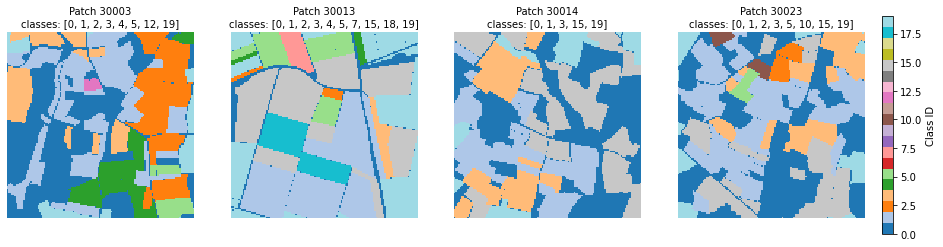

In [15]:
# --- B.6: label maps of the first four patches (tab20 colours, one per class ID) ---
show_ids = common_ids[:4]

fig, axes = plt.subplots(1, len(show_ids), figsize=(4 * len(show_ids), 4))

for ax, pid in zip(axes, show_ids):
    lab = np.load(ANN_DIR / f"TARGET_{pid}.npy")[0]   # (H, W)

    im = ax.imshow(lab, cmap="tab20", vmin=0, vmax=19, interpolation="nearest")
    ax.set_title(f"Patch {pid}\nclasses: {sorted(np.unique(lab).tolist())}", fontsize=10)
    ax.axis("off")

fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Class ID")
plt.savefig(FIG_DIR / "label_patches.png", dpi=150, bbox_inches="tight")
plt.show()


### B.7 — Visualisation of Sentinel-2 imagery using an appropriate RGB-band combination
RGB = B4 (Red), B3 (Green), B2 (Blue). Each patch shows its clearest date, and reflectance is linearly stretched for visibility.

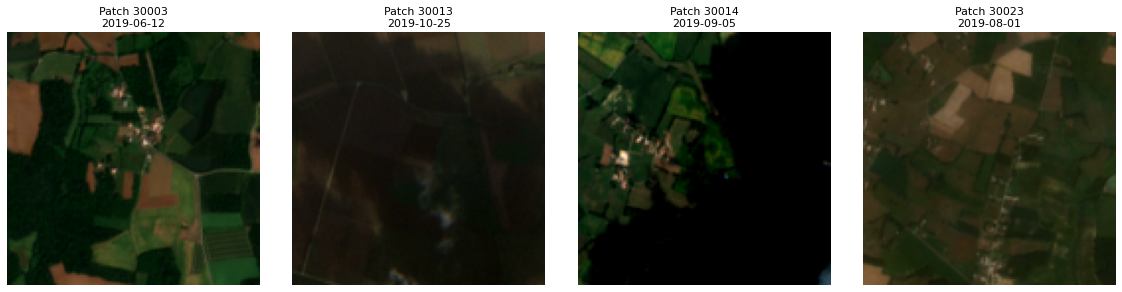

In [16]:
# --- B.7: true-colour RGB (B4, B3, B2) of the same four patches, on each patch's clearest date ---
show_ids = common_ids[:4]

fig, axes = plt.subplots(1, len(show_ids), figsize=(4 * len(show_ids), 4))

for ax, pid in zip(axes, show_ids):
    s2 = np.load(S2_DIR / f"S2_{pid}.npy").astype(np.float32) / 10000.0   # (T, C, H, W), reflectance

    # Pick the clearest date: lowest mean blue (B2, band index 0) across the patch
    t = int(np.argmin(s2[:, 0].mean(axis=(1, 2))))

    # RGB = B4 (Red, index 2), B3 (Green, index 1), B2 (Blue, index 0)
    rgb = s2[t, [2, 1, 0]].transpose(1, 2, 0)      # (H, W, 3)

    # Stretch for display: reflectance values are naturally dim
    rgb_stretched = np.clip(rgb / 0.3, 0, 1)

    ax.imshow(rgb_stretched)
    ax.set_title(f"Patch {pid}\n{dates[t].date()}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "rgb_visualisation.png", dpi=150)
plt.show()


### B.8 — AOI extent or approximate geographic coverage
Metadata polygons are in EPSG:2154 (French national CRS, Lambert-93). Building a GeoDataFrame manually from the raw GeoJSON avoids a broken `fiona` install; only `shapely` and `geopandas`'s CRS-conversion are needed.

CRS      : EPSG:2154
Tile(s)  : ['t31tfm']

Bounding box (EPSG:2154, metres):
  X: 848544 to 881796  (width  = 33,252 m)
  Y: 6613305 to 6649117  (height = 35,812 m)

Bounding box (WGS84, lat/lon):
  Lon: 4.9441 to 5.3826
  Lat: 46.5972 to 46.9251
  Centre: 46.7737, 5.1593


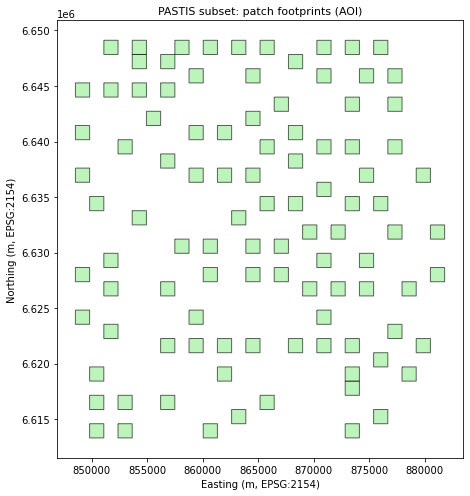

In [17]:
# --- B.8: AOI extent from the patch footprints in metadata.geojson ---
with open(META_FP, "r") as f:
    meta = json.load(f)

feats = [ft for ft in meta["features"] if ft["properties"]["ID_PATCH"] in common_ids]

gdf = gpd.GeoDataFrame(
    [ft["properties"] for ft in feats],
    geometry=[shape(ft["geometry"]) for ft in feats],
    crs="EPSG:2154",
)
gdf = gdf.set_index("ID_PATCH").loc[common_ids]

print("CRS      :", gdf.crs)
print("Tile(s)  :", gdf["TILE"].unique())

# --- Bounding box, native CRS (metres) ---
minx, miny, maxx, maxy = gdf.total_bounds
print(f"\nBounding box (EPSG:2154, metres):")
print(f"  X: {minx:.0f} to {maxx:.0f}  (width  = {maxx - minx:,.0f} m)")
print(f"  Y: {miny:.0f} to {maxy:.0f}  (height = {maxy - miny:,.0f} m)")

# --- Bounding box in lat/lon ---
gdf_wgs84 = gdf.to_crs(epsg=4326)
lon_min, lat_min, lon_max, lat_max = gdf_wgs84.total_bounds
centre = gdf_wgs84.unary_union.centroid
print(f"\nBounding box (WGS84, lat/lon):")
print(f"  Lon: {lon_min:.4f} to {lon_max:.4f}")
print(f"  Lat: {lat_min:.4f} to {lat_max:.4f}")
print(f"  Centre: {centre.y:.4f}, {centre.x:.4f}")

# --- Map of patch footprints ---
fig, ax = plt.subplots(figsize=(7, 7))
gdf.plot(ax=ax, edgecolor="black", facecolor="lightgreen", alpha=0.6)
ax.set_title("PASTIS subset: patch footprints (AOI)", fontsize=11)
ax.set_xlabel("Easting (m, EPSG:2154)")
ax.set_ylabel("Northing (m, EPSG:2154)")
plt.tight_layout()
plt.savefig(FIG_DIR / "aoi_extent.png", dpi=150)
plt.show()


### B.9 — Any useful information you can infer about the agricultural landscape

- **Location:** centre approx. 46.77 N, 5.16 E — eastern France (Jura / Saône-et-Loire area), single Sentinel-2 tile `t31tfm`. Derived from the metadata CRS/coordinates.
- **AOI shape:** 102 patches of 1.28 x 1.28 km scattered irregularly across a ~33 x 36 km bounding box (not full coverage).
- **Time span:** 2018-09-20 to 2019-10-25, i.e. one full agricultural year --> consistent with the mix of winter cereals (sown autumn, harvested summer) and summer crops such as corn/soybeans (sown spring, harvested autumn) seen in the class list.
- **Class imbalance:** background and a handful of major crop classes dominate; several classes appear in only 1-3 patches (see B.5), which will need to be handled explicitly for Task D/E.
- **Cloud contamination:** some dates show bright, high-reflectance pixels consistent with cloud cover; B.10 below quantifies this per date. All 46 dates are kept as-is per the preprocessing decision in Task A; this is a documented limitation, not a correction.

### B.10 — Cloud contamination per date

Sentinel-2 L2A reflectance of vegetation and bare soil in the blue band (B2) is normally well below 0.2, while clouds are bright in all visible bands. As a simple proxy (no cloud mask is provided), a pixel is flagged as cloud-like on a date if its B2 reflectance is above 0.2. For each date, the share of flagged pixels is computed over all 102 patches. This is a rough heuristic: it misses thin cloud and cloud shadow, and can flag very bright bare surfaces, but it shows how often the time series is affected.

Dates with >10% cloud-like pixels over the whole AOI: 17 of 46
Cloudy dates per patch (>10% of the patch flagged): median 10, min 5, max 16 (of 46)

Most affected dates:
      date  pct_cloud_like
2018-10-10           99.99
2018-11-04           99.99
2019-08-11           97.71
2019-06-07           71.25
2019-02-12           56.51
2019-05-03           42.59
2019-07-12           41.22
2019-10-25           36.60
2019-01-28           32.64
2018-12-19           30.19


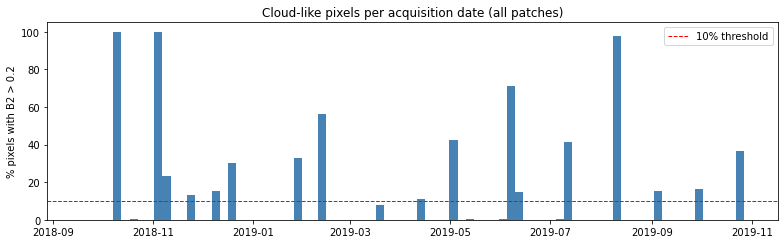

In [18]:
# --- B.10: share of cloud-like pixels (B2 reflectance > 0.2) per date ---
CLOUD_B2_THRESHOLD = 0.2   # reflectance; clear vegetation/soil is typically well below this
PATCH_CLOUD_LIMIT  = 0.10  # a date counts as "cloudy" for a patch if >10% of its pixels are flagged

n_dates = len(dates)
flagged_px = np.zeros(n_dates, dtype=np.int64)   # flagged pixels per date, summed over patches
cloudy_dates_per_patch = {}                      # patch_id -> number of dates above PATCH_CLOUD_LIMIT

for pid in common_ids:
    # Read only the blue band (index 0) of every date; memory-mapped so the full array is not loaded
    s2 = np.load(S2_DIR / f"S2_{pid}.npy", mmap_mode="r")
    blue = np.asarray(s2[:, 0]).astype(np.float32) / 10000.0           # (T, H, W)
    frac = (blue > CLOUD_B2_THRESHOLD).mean(axis=(1, 2))                # share flagged, per date
    flagged_px += (blue > CLOUD_B2_THRESHOLD).sum(axis=(1, 2))
    cloudy_dates_per_patch[pid] = int((frac > PATCH_CLOUD_LIMIT).sum())

px_per_date = len(common_ids) * blue.shape[1] * blue.shape[2]
df_cloud = pd.DataFrame({"date": dates.date, "pct_cloud_like": np.round(100 * flagged_px / px_per_date, 2)})

# --- Summary ---
n_cloudy = pd.Series(cloudy_dates_per_patch)
print(f"Dates with >10% cloud-like pixels over the whole AOI: "
      f"{int((df_cloud['pct_cloud_like'] > 10).sum())} of {n_dates}")
print(f"Cloudy dates per patch (>10% of the patch flagged): "
      f"median {n_cloudy.median():.0f}, min {n_cloudy.min()}, max {n_cloudy.max()} (of {n_dates})")
print("\nMost affected dates:")
print(df_cloud.sort_values("pct_cloud_like", ascending=False).head(10).to_string(index=False))

# --- Plot: share of cloud-like pixels over time ---
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(pd.to_datetime(df_cloud["date"]), df_cloud["pct_cloud_like"], width=5, color="steelblue")
ax.axhline(10, color="red", linestyle="--", linewidth=1, label="10% threshold")
ax.set_ylabel("% pixels with B2 > 0.2")
ax.set_title("Cloud-like pixels per acquisition date (all patches)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "cloud_fraction_per_date.png", dpi=150)
plt.show()

df_cloud.to_csv(METRICS_DIR / "cloud_fraction_per_date.csv", index=False)

## Task C: Train / Validation / Test Split

### Split strategy

The split is done **by patch**, not by pixel: pixels within a patch are spatially correlated (neighbouring fields, shared crop boundaries), so splitting at the pixel level would let information leak between train and test and inflate the scores.

The metadata already provides a `Fold` column (1-5), a pre-assigned spatial partition of the patches. Using it directly avoids introducing any new randomness and keeps the split fully reproducible from the data alone:

- **Train:** folds 1, 2, 3
- **Validation:** fold 4
- **Test:** fold 5

From the fold sizes (20, 23, 23, 18, 18 patches), this gives roughly a 65% / 18% / 18% train/val/test split by patch count.

**Note:** this fixed split leaves some classes absent from the validation and/or test folds (see the per-fold class check below), so the evaluation in Task E is complemented by a 5-fold rotating cross-validation that uses every fold as the test set once.

In [19]:
# --- Assign each patch to train / val / test using the Fold column ---
fold_of_patch = df_meta["Fold"].to_dict()   # {patch_id: fold}

train_ids = sorted([pid for pid in common_ids if fold_of_patch[pid] in (1, 2, 3)])
val_ids   = sorted([pid for pid in common_ids if fold_of_patch[pid] == 4])
test_ids  = sorted([pid for pid in common_ids if fold_of_patch[pid] == 5])

print(f"Train patches : {len(train_ids)}  ({100 * len(train_ids) / len(common_ids):.1f}%)")
print(f"Val patches   : {len(val_ids)}  ({100 * len(val_ids) / len(common_ids):.1f}%)")
print(f"Test patches  : {len(test_ids)}  ({100 * len(test_ids) / len(common_ids):.1f}%)")
print(f"Total         : {len(train_ids) + len(val_ids) + len(test_ids)} (expected {len(common_ids)})")

# --- Sanity check: no patch appears in more than one split ---
assert set(train_ids) & set(val_ids) == set()
assert set(train_ids) & set(test_ids) == set()
assert set(val_ids) & set(test_ids) == set()
print("\nNo overlap between splits: confirmed")


Train patches : 66  (64.7%)
Val patches   : 18  (17.6%)
Test patches  : 18  (17.6%)
Total         : 102 (expected 102)

No overlap between splits: confirmed


In [20]:
# --- Which classes are present in each fold? (void 19 excluded) ---
# Motivates the rotating cross-validation in Task E: with a single fixed split,
# any class missing from the val or test fold cannot be evaluated there.

# PASTIS class names (defined here so this cell runs on its own; Task E reuses the same mapping)
class_names = {0: "Background", 1: "Meadow", 2: "Soft winter wheat", 3: "Corn", 4: "Winter barley",
               5: "Winter rapeseed", 6: "Spring barley", 7: "Sunflower", 8: "Grapevine", 9: "Beet",
               10: "Winter triticale", 11: "Winter durum wheat", 12: "Fruits/veg/flowers",
               13: "Potatoes", 14: "Leguminous fodder", 15: "Soybeans", 16: "Orchard",
               17: "Mixed cereal", 18: "Sorghum", 19: "Void"}

FOLDS = [1, 2, 3, 4, 5]

# Collect the set of (non-void) classes found in the pixels of each fold
fold_classes = {}
for f in FOLDS:
    ids  = [p for p in common_ids if fold_of_patch[p] == f]
    labs = y[np.isin(patch_of_pixel, ids)]
    fold_classes[f] = set(np.unique(labs[labs != 19]).tolist())

# All classes that occur anywhere in the dataset
all_cls = sorted(set().union(*fold_classes.values()))
print(f"Classes in the full dataset (excluding void): {len(all_cls)}\n")

# For each fold, list the classes that do NOT occur in it
for f in FOLDS:
    missing = [f"{c}:{class_names.get(c, '?')}" for c in all_cls if c not in fold_classes[f]]
    print(f"Fold {f}: {len(fold_classes[f]):>2} classes present, missing -> {missing if missing else 'none'}")

# Presence matrix: 1 = class occurs in the fold, 0 = absent
df_fold_presence = pd.DataFrame(
    {f"fold_{f}": [int(c in fold_classes[f]) for c in all_cls] for f in FOLDS},
    index=[f"{c}:{class_names.get(c, '?')}" for c in all_cls],
)
print("\nClass presence per fold (1 = present):")
print(df_fold_presence.to_string())

Classes in the full dataset (excluding void): 18

Fold 1: 15 classes present, missing -> ['12:Fruits/veg/flowers', '13:Potatoes', '16:Orchard']
Fold 2: 15 classes present, missing -> ['7:Sunflower', '8:Grapevine', '11:Winter durum wheat']
Fold 3: 14 classes present, missing -> ['8:Grapevine', '11:Winter durum wheat', '13:Potatoes', '16:Orchard']
Fold 4: 14 classes present, missing -> ['8:Grapevine', '13:Potatoes', '16:Orchard', '18:Sorghum']
Fold 5: 15 classes present, missing -> ['8:Grapevine', '13:Potatoes', '16:Orchard']

Class presence per fold (1 = present):
                       fold_1  fold_2  fold_3  fold_4  fold_5
0:Background                1       1       1       1       1
1:Meadow                    1       1       1       1       1
2:Soft winter wheat         1       1       1       1       1
3:Corn                      1       1       1       1       1
4:Winter barley             1       1       1       1       1
5:Winter rapeseed           1       1       1       1     

### Save the patch IDs for each split
Saved as plain text files, one patch ID per line, so the split can be reproduced exactly without rerunning the fold assignment logic.

In [21]:
# --- Save one patch ID per line, in a dedicated splits folder ---
# SPLIT_DIR is defined in the paths cell (Task A)
for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]:
    fp = SPLIT_DIR / f"{name}_patch_ids.txt"
    with open(fp, "w") as f:
        f.write("\n".join(str(pid) for pid in ids))
    print(f"Saved {len(ids):>3} patch IDs -> {fp}")


Saved  66 patch IDs -> D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\splits\train_patch_ids.txt
Saved  18 patch IDs -> D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\splits\val_patch_ids.txt
Saved  18 patch IDs -> D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\splits\test_patch_ids.txt


### Apply the split to the pixel-level training table
Uses `patch_of_pixel` (built in Task A) to select which rows of `X`/`y` belong to each split, without rebuilding the feature table.

In [22]:
# --- Boolean masks over the pixel table, based on each pixel's patch ID ---
train_mask = np.isin(patch_of_pixel, train_ids)
val_mask   = np.isin(patch_of_pixel, val_ids)
test_mask  = np.isin(patch_of_pixel, test_ids)

X_train, y_train = X[train_mask], y[train_mask]
X_val,   y_val   = X[val_mask],   y[val_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(f"X_train : {X_train.shape}")
print(f"X_val   : {X_val.shape}")
print(f"X_test  : {X_test.shape}")
print(f"\nRow count check: {X_train.shape[0] + X_val.shape[0] + X_test.shape[0]} (expected {X.shape[0]})")


X_train : (1081344, 460)
X_val   : (294912, 460)
X_test  : (294912, 460)

Row count check: 1671168 (expected 1671168)


# Task D: Model Training

## Input features and preprocessing

* **Input features:** the 460-column pixel table (`X_train`, `X_val`, `X_test`) from Task A — 46 acquisition dates x 10 Sentinel-2 bands, reflectance-scaled (divided by 10000), all dates kept as-is.
* **No further normalization:** Random Forest is a tree-based model and splits on raw feature values, so it does not require feature scaling (unlike distance-based models such as SVM).
* **Class exclusion:** class 19 (Void) is removed from all three splits before training and evaluation, since it has no real spectral signature (unlabelled pixels, not a land-cover class). Class 0 (Background) is kept, as it is a genuine, learnable class.
* **Class imbalance:** handled via `class_weight="balanced"` in the Random Forest itself, rather than resampling the data. This reweights each class inversely to its frequency during training, so rare classes (e.g. Orchard, Potatoes) still influence the model despite their small pixel counts, without discarding any majority-class data. Evaluation also relies on macro-averaged precision, recall, MCC and F1 (alongside per-class scores) rather than overall accuracy alone, since accuracy alone would look artificially high due to the dominant classes and would hide poor performance on rare ones.

In [23]:
# --- Remove void (19) pixels from all splits ---
def drop_void(Xs, ys):
    mask = ys != 19
    return Xs[mask], ys[mask]

X_train_m, y_train_m = drop_void(X_train, y_train)
X_val_m,   y_val_m   = drop_void(X_val,   y_val)
X_test_m,  y_test_m  = drop_void(X_test,  y_test)

print(f"Train: {X_train.shape[0]} -> {X_train_m.shape[0]} rows ({X_train.shape[0]-X_train_m.shape[0]} void removed)")
print(f"Val  : {X_val.shape[0]} -> {X_val_m.shape[0]} rows ({X_val.shape[0]-X_val_m.shape[0]} void removed)")
print(f"Test : {X_test.shape[0]} -> {X_test_m.shape[0]} rows ({X_test.shape[0]-X_test_m.shape[0]} void removed)")
print(f"\nClasses remaining: {sorted(np.unique(y_train_m).tolist())}")

Train: 1081344 -> 987951 rows (93393 void removed)
Val  : 294912 -> 267316 rows (27596 void removed)
Test : 294912 -> 271814 rows (23098 void removed)

Classes remaining: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18]


## Hyperparameters and training configuration

Starting configuration for a Random Forest baseline, chosen for interpretability and to avoid overfitting given some classes have very few training pixels:

| Parameter | Value | Reason |
|---|---|---|
| `n_estimators` | 200 | Enough trees for stable predictions without excessive training time |
| `max_depth` | 20 | Limits overfitting on rare classes; unlimited depth risks memorizing them |
| `min_samples_leaf` | 5 | Avoids leaves fit to a single noisy pixel |
| `class_weight` | `"balanced"` | Compensates for the class imbalance documented in Task B |
| `n_jobs` | -1 | Uses all available CPU cores (compute environment: local machine, no GPU) |
| `random_state` | 0 (Fixed) | Reproducibility |

In [24]:
# --- Main Random Forest (fixed split: train folds 1-3); settings explained in the table above ---
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    class_weight="balanced",
    n_jobs=-1,
    random_state=0,
    verbose=1,
)

# Time the fit, since training cost matters for the CV and leave-one-out discussion
start = time.time()
rf.fit(X_train_m, y_train_m)
elapsed = time.time() - start

print(f"\nTraining time: {elapsed:.1f} seconds")
print(f"Training samples: {X_train_m.shape[0]}, features: {X_train_m.shape[1]}")
print(f"Classes learned: {sorted(rf.classes_.tolist())}")

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed: 17.6min



Training time: 1147.7 seconds
Training samples: 987951, features: 460
Classes learned: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18]


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 19.1min finished


## Save the trained model

The model is saved with `joblib`, the standard format for scikit-learn models. If the resulting file is too large for the GitHub repo, it is excluded from the repo and reproduced instead by re-running Task A (data loading/preprocessing) through this training cell — the steps are fully deterministic (`random_state=0`), so re-running reproduces the same model.

The file is written to `outputs/models/rf_model.joblib` (~765 MB). This folder is listed in `.gitignore`, and the README explains how to regenerate the model, either by running this notebook or with `python src/train.py`.

In [25]:
# --- Save the fitted model (joblib is the standard format for scikit-learn) ---
MODEL_FP = MODEL_DIR / "rf_model.joblib"   # outputs/models/, git-ignored
joblib.dump(rf, MODEL_FP)

print(f"Model saved to: {MODEL_FP}")
print(f"File size: {MODEL_FP.stat().st_size / 1e6:.1f} MB")

Model saved to: D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\outputs\models\rf_model.joblib
File size: 765.2 MB


# Task E: Model Evaluation

The model is evaluated on both validation and test sets (void pixels excluded, same as training). Validation and test come from separate patches (Task C), so test results reflect generalization to entirely unseen locations.

In [26]:
# --- Predict on val and test ---
y_val_pred  = rf.predict(X_val_m)
y_test_pred = rf.predict(X_test_m)

# --- Overall accuracy ---
val_acc  = accuracy_score(y_val_m, y_val_pred)
test_acc = accuracy_score(y_test_m, y_test_pred)

print(f"Validation accuracy : {val_acc:.4f}")
print(f"Test accuracy        : {test_acc:.4f}")

# --- Save overall accuracy ---
pd.DataFrame({"split": ["val", "test"], "accuracy": [val_acc, test_acc]}).to_csv(
    METRICS_DIR / "fixed_split_accuracy.csv", index=False)

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.8s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    4.3s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    4.6s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.8s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    4.4s


Validation accuracy : 0.8519
Test accuracy        : 0.8386


[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    4.7s finished


In [27]:
# --- Per-class precision / recall / F1 and MCC on validation and test ---
class_names = {0: "Background", 1: "Meadow", 2: "Soft winter wheat", 3: "Corn", 4: "Winter barley",
               5: "Winter rapeseed", 6: "Spring barley", 7: "Sunflower", 8: "Grapevine",
               10: "Winter triticale", 11: "Winter durum wheat", 12: "Fruits/veg/flowers",
               13: "Potatoes", 14: "Leguminous fodder", 15: "Soybeans", 16: "Orchard",
               17: "Mixed cereal", 18: "Sorghum"}

present_classes = sorted(np.unique(y_test_m).tolist())
target_names = [f"{c}:{class_names.get(c, '?')}" for c in present_classes]

print("=" * 70)
print("VALIDATION — per-class precision / recall / F1")
print("=" * 70)
print(classification_report(y_val_m, y_val_pred, labels=present_classes,
                             target_names=target_names, zero_division=0))
val_mcc = matthews_corrcoef(y_val_m, y_val_pred)
print(f"Matthews Correlation Coefficient (MCC): {val_mcc:.4f}")

print("\n" + "=" * 70)
print("TEST — per-class precision / recall / F1")
print("=" * 70)
print(classification_report(y_test_m, y_test_pred, labels=present_classes,
                             target_names=target_names, zero_division=0))
test_mcc = matthews_corrcoef(y_test_m, y_test_pred)
print(f"Matthews Correlation Coefficient (MCC): {test_mcc:.4f}")

# --- Save per-class reports as CSV (one file per split) ---
for split, yt, yp in [("val", y_val_m, y_val_pred), ("test", y_test_m, y_test_pred)]:
    report_dict = classification_report(yt, yp, labels=present_classes, target_names=target_names,
                                zero_division=0, output_dict=True)
    pd.DataFrame(report_dict).T.round(4).to_csv(METRICS_DIR / f"fixed_split_classification_report_{split}.csv")
pd.DataFrame({"split": ["val", "test"], "MCC": [val_mcc, test_mcc]}).to_csv(
    METRICS_DIR / "fixed_split_mcc.csv", index=False)

VALIDATION — per-class precision / recall / F1
                       precision    recall  f1-score   support

         0:Background       0.83      0.80      0.82     81644
             1:Meadow       0.72      0.76      0.74     43893
  2:Soft winter wheat       0.85      0.96      0.91     48749
               3:Corn       0.94      0.94      0.94     37772
      4:Winter barley       0.91      0.95      0.93     10730
    5:Winter rapeseed       0.96      0.97      0.96     19554
      6:Spring barley       0.00      0.00      0.00      1188
          7:Sunflower       0.99      0.63      0.77      2121
  10:Winter triticale       0.96      0.36      0.52      3268
11:Winter durum wheat       0.00      0.00      0.00       172
12:Fruits/veg/flowers       0.00      0.00      0.00        86
 14:Leguminous fodder       1.00      0.11      0.20      1964
          15:Soybeans       0.90      0.93      0.91     15959
      17:Mixed cereal       0.00      0.00      0.00       216
       

In [28]:
# --- mIoU: mean Jaccard (intersection-over-union) across classes present in each set ---
val_iou_per_class  = jaccard_score(y_val_m,  y_val_pred,  labels=present_classes, average=None, zero_division=0)
test_iou_per_class = jaccard_score(y_test_m, y_test_pred, labels=present_classes, average=None, zero_division=0)

df_iou = pd.DataFrame({
    "class_id": present_classes,
    "name": [class_names.get(c, "?") for c in present_classes],
    "val_IoU": np.round(val_iou_per_class, 3),
    "test_IoU": np.round(test_iou_per_class, 3),
})
print(df_iou.to_string(index=False))

print(f"\nValidation mIoU (mean over present classes): {val_iou_per_class.mean():.4f}")
print(f"Test mIoU (mean over present classes)      : {test_iou_per_class.mean():.4f}")

# --- Save per-class IoU ---
df_iou.to_csv(METRICS_DIR / "fixed_split_iou_per_class.csv", index=False)

 class_id               name  val_IoU  test_IoU
        0         Background    0.688     0.680
        1             Meadow    0.588     0.620
        2  Soft winter wheat    0.828     0.875
        3               Corn    0.891     0.867
        4      Winter barley    0.870     0.863
        5    Winter rapeseed    0.928     0.912
        6      Spring barley    0.000     0.000
        7          Sunflower    0.627     0.751
       10   Winter triticale    0.353     0.011
       11 Winter durum wheat    0.000     0.000
       12 Fruits/veg/flowers    0.000     0.000
       14  Leguminous fodder    0.109     0.104
       15           Soybeans    0.840     0.843
       17       Mixed cereal    0.000     0.000
       18            Sorghum    0.000     0.000

Validation mIoU (mean over present classes): 0.4482
Test mIoU (mean over present classes)      : 0.4350


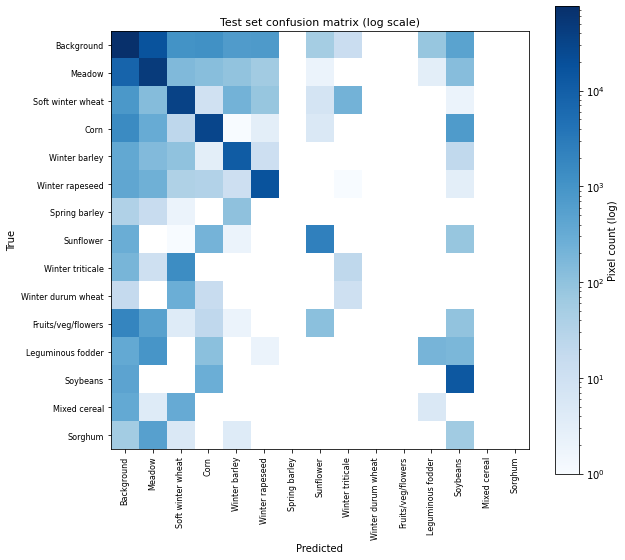

In [29]:
# --- Confusion matrix (test set) ---
cm = confusion_matrix(y_test_m, y_test_pred, labels=present_classes)
# Save the raw counts too, so the matrix can be inspected without the figure
pd.DataFrame(cm, index=[class_names.get(c, '?') for c in present_classes],
             columns=[class_names.get(c, '?') for c in present_classes]).to_csv(METRICS_DIR / "confusion_matrix_test.csv")

# Log colour scale: otherwise the large classes swamp the rare ones

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues", norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=cm.max()))
ax.set_xticks(range(len(present_classes)))
ax.set_yticks(range(len(present_classes)))
ax.set_xticklabels([class_names.get(c, "?") for c in present_classes], rotation=90, fontsize=8)
ax.set_yticklabels([class_names.get(c, "?") for c in present_classes], fontsize=8)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Test set confusion matrix (log scale)", fontsize=11)
fig.colorbar(im, ax=ax, label="Pixel count (log)")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_test.png", dpi=150)
plt.show()

### Metrics split by class support

To separate genuine model performance from the effect of limited training data, classes are split into two groups based on how many patches they appear in (from Task B): well-represented (≥25 patches) and sparse (<25 patches). A macro-average computed only on the well-represented group shows how the model performs where it has adequate data.

In [30]:
# --- Patch-count-based grouping (from Task B's df_dist) ---
patches_present = df_dist.set_index("class_id")["patches_present"].to_dict()

well_represented = [c for c in present_classes if patches_present.get(c, 0) >= 25]
sparse           = [c for c in present_classes if patches_present.get(c, 0) < 25]

print("Well-represented classes (>=25 patches):", [f"{c}:{class_names.get(c,'?')}" for c in well_represented])
print("Sparse classes (<25 patches)           :", [f"{c}:{class_names.get(c,'?')}" for c in sparse])

# --- Macro-average metrics restricted to each group (test set) ---

def binary_mcc(y_true, y_pred, c):
    """One-vs-rest MCC for class c, computed from counts (float64 to avoid overflow)."""
    t = (y_true == c)
    p = (y_pred == c)
    tp = np.float64(np.sum(t & p))
    fp = np.float64(np.sum(~t & p))
    fn = np.float64(np.sum(t & ~p))
    tn = np.float64(t.size) - tp - fp - fn
    denom = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom

def macro_for_group(y_true, y_pred, group):
    if len(group) == 0:
        return (np.nan,) * 5
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=group, average="macro", zero_division=0)
    iou = jaccard_score(y_true, y_pred, labels=group, average="macro", zero_division=0)
    mcc = np.mean([binary_mcc(y_true, y_pred, c) for c in group])
    return p, r, f1, iou, mcc

p_wr, r_wr, f1_wr, iou_wr, mcc_wr         = macro_for_group(y_test_m, y_test_pred, well_represented)
p_sp, r_sp, f1_sp, iou_sp, mcc_sp         = macro_for_group(y_test_m, y_test_pred, sparse)
p_all, r_all, f1_all, iou_all, mcc_all    = macro_for_group(y_test_m, y_test_pred, present_classes)

df_group = pd.DataFrame({
    "group": ["Well-represented (>=25 patches)", "Sparse (<25 patches)", "All classes"],
    "n_classes": [len(well_represented), len(sparse), len(present_classes)],
    "macro_precision": np.round([p_wr, p_sp, p_all], 3),
    "macro_recall": np.round([r_wr, r_sp, r_all], 3),
    "macro_f1": np.round([f1_wr, f1_sp, f1_all], 3),
    "macro_IoU": np.round([iou_wr, iou_sp, iou_all], 3),
    "macro_MCC": np.round([mcc_wr, mcc_sp, mcc_all], 3),
})
print("\nTest set — macro-averaged metrics by class support:")
print(df_group.to_string(index=False))

# Optional: standard multiclass MCC over all pixels, for reference
mcc_multiclass = matthews_corrcoef(np.asarray(y_test_m).ravel(), np.asarray(y_test_pred).ravel())
print(f"\nOverall multiclass MCC (all pixels): {mcc_multiclass:.3f}")

# --- Save the group table ---
df_group.to_csv(METRICS_DIR / "fixed_split_metrics_by_class_support.csv", index=False)

Well-represented classes (>=25 patches): ['0:Background', '1:Meadow', '2:Soft winter wheat', '3:Corn', '4:Winter barley', '5:Winter rapeseed', '10:Winter triticale', '14:Leguminous fodder', '15:Soybeans']
Sparse classes (<25 patches)           : ['6:Spring barley', '7:Sunflower', '11:Winter durum wheat', '12:Fruits/veg/flowers', '17:Mixed cereal', '18:Sorghum']

Test set — macro-averaged metrics by class support:
                          group  n_classes  macro_precision  macro_recall  macro_f1  macro_IoU  macro_MCC
Well-represented (>=25 patches)          9            0.766         0.720     0.716      0.642      0.705
           Sparse (<25 patches)          6            0.154         0.133     0.143      0.125      0.143
                    All classes         15            0.521         0.485     0.487      0.435      0.480

Overall multiclass MCC (all pixels): 0.798


### Why a rotating 5-fold split instead of a single fixed split

**The initial approach.** Task C used the `Fold` column as a single fixed patch-level split: folds 1, 2, 3 for training, fold 4 for validation and fold 5 for testing (66 / 18 / 18 patches).

**The problem: classes missing from some folds.** Because the folds are spatial partitions of only 102 patches, crop types are not spread evenly across them. Several of the rarer classes occur in only a handful of patches (B.5), and those patches fall into only some of the folds (see the per-fold class check in Task C). With the fixed split:

- Grapevine (8), Potatoes (13) and Orchard (16) each occur in a single patch, and all three of those patches are in the training folds, so these classes are **absent from both validation and test** and cannot be evaluated at all;
- Sorghum (18) is **absent from the validation fold** (support 0 in the validation report above), so it cannot be monitored during model development;
- the reported test score depends heavily on *which* 18 patches happen to be in fold 5, and describes the model's behaviour on only ~18% of the data.

**The solution: rotating the roles of the folds.** Instead of one split, five rounds are run. In each round one fold is the test set, the fold before it is the validation set, and the remaining three folds are the training set:

| Round | Train | Validation | Test |
|---|---|---|---|
| 1 | 2, 3, 4 | 5 | 1 |
| 2 | 3, 4, 5 | 1 | 2 |
| 3 | 1, 4, 5 | 2 | 3 |
| 4 | 1, 2, 5 | 3 | 4 |
| 5 | 1, 2, 3 | 4 | 5 |

Round 5 is identical to the original split, and reproduces its results exactly (test accuracy 0.839, MCC 0.798), which confirms the loop is consistent with Tasks C–E. Across the five rounds, every patch is used for testing exactly once, for validation exactly once and for training three times, so all 102 patches, and every class, contribute to the evaluation. A new Random Forest with the same hyperparameters as Task D is trained from scratch in each round, and the split remains at patch level, so there is no spatial leakage between train, validation and test. The patch IDs of every round are saved to text files, as for the main split.

Two kinds of test score are reported:

- **Mean ± std across the 5 rounds.** Each round's model is scored on its own test fold and the five scores are averaged. This is the cross-validated test performance, and the standard deviation shows how sensitive the result is to which patches are held out.
- **Pooled out-of-fold (OOF) predictions.** The five test folds are concatenated, so every pixel has exactly one prediction from a model that never saw its patch, and metrics are computed once on the combined set. This is used for the per-class and well-represented vs. sparse analysis, because rare classes are evaluated on all of their pixels at once instead of being split across (or missing from) individual folds.

**A caveat for single-patch classes.** Grapevine, Potatoes and Orchard each exist in only one patch. In the round where that patch is in the test fold, the model has seen *zero* training examples of the class, so it cannot predict it. Their cross-validated scores therefore show that a class with no training examples cannot be learned; they say nothing about how well the model would do with adequate data.

**Why not leave-one-out?** A leave-one-out design was also considered. At the pixel level it would be invalid, because neighbouring pixels are spatially correlated, so it would leak information in the same way as a random pixel split. At the patch level (leave-one-patch-out) it would mean training 102 Random Forests, one per held-out patch: roughly 20x the cost of 5-fold CV, with each Task D training run already taking ~36 minutes. Each test set would also be a single 128x128 patch containing only a few classes, which makes the per-round scores very noisy. It would also have no natural place for a separate validation set, and patches from the same spatial fold would still end up in training, which weakens the spatial independence the `Fold` column provides. The rotating 5-fold scheme is effectively a **leave-one-fold-out** design: it keeps the pre-defined spatial folds intact, gives every patch a turn in the test set, and stays computationally affordable.

Loop variables in the code below are named `rf_cv`, `tr_ids`, `va_ids`, `te_ids` so that the main model `rf` and `test_ids` used in Task F are not overwritten.

In [31]:
# --- 5-fold rotating train / val / test (patch-level, using the Fold column) ---

FOLDS = [1, 2, 3, 4, 5]

# Per-round split IDs go in splits/cv/; metric tables in outputs/metrics/ (METRICS_DIR, paths cell)
CV_SPLIT_DIR = SPLIT_DIR / "cv"
CV_SPLIT_DIR.mkdir(parents=True, exist_ok=True)

cv_rows = []                 # one row of metrics per (round, split)
oof_true, oof_pred = [], []  # pooled out-of-fold test labels / predictions

for k in range(len(FOLDS)):
    # --- Assign fold roles for this round (matches the table above: round k tests fold k) ---
    test_fold   = FOLDS[k]                                              # round 1 -> fold 1, ..., round 5 -> fold 5
    val_fold    = FOLDS[(k + 4) % 5]                                    # fold just before the test fold
    train_folds = [f for f in FOLDS if f not in (test_fold, val_fold)]  # the remaining three folds

    # --- Patch IDs per split (named differently from Task C's train_ids / val_ids / test_ids) ---
    tr_ids = sorted(p for p in common_ids if fold_of_patch[p] in train_folds)
    va_ids = sorted(p for p in common_ids if fold_of_patch[p] == val_fold)
    te_ids = sorted(p for p in common_ids if fold_of_patch[p] == test_fold)

    # Sanity check: no patch appears in more than one split
    assert not (set(tr_ids) & set(va_ids) or set(tr_ids) & set(te_ids) or set(va_ids) & set(te_ids))

    # Save this round's patch IDs, one per line, so every round can be reproduced exactly
    for name, ids in [("train", tr_ids), ("val", va_ids), ("test", te_ids)]:
        with open(CV_SPLIT_DIR / f"round{k+1}_{name}_patch_ids.txt", "w") as f:
            f.write("\n".join(str(pid) for pid in ids))

    # --- Select this round's pixel rows and drop void (19), exactly as in Task D ---
    tr_mask = np.isin(patch_of_pixel, tr_ids)
    va_mask = np.isin(patch_of_pixel, va_ids)
    te_mask = np.isin(patch_of_pixel, te_ids)

    X_tr, y_tr = drop_void(X[tr_mask], y[tr_mask])
    X_va, y_va = drop_void(X[va_mask], y[va_mask])
    X_te, y_te = drop_void(X[te_mask], y[te_mask])

    # --- Fresh Random Forest with the same hyperparameters as the main model (Task D) ---
    rf_cv = RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=0,
    )
    start = time.time()
    rf_cv.fit(X_tr, y_tr)
    elapsed = time.time() - start

    # --- Score on this round's validation and test folds ---
    for split, Xs, ys in [("val", X_va, y_va), ("test", X_te, y_te)]:
        yp = rf_cv.predict(Xs)
        p, r, f1, _ = precision_recall_fscore_support(ys, yp, average="macro", zero_division=0)
        cv_rows.append({
            "round": k + 1, "split": split,
            "train_folds": ",".join(map(str, train_folds)),
            "val_fold": val_fold, "test_fold": test_fold,
            "n_classes_present": len(np.unique(ys)),   # classes that could be evaluated this round
            "accuracy": accuracy_score(ys, yp),
            "macro_precision": p, "macro_recall": r, "macro_f1": f1,
            "macro_IoU": jaccard_score(ys, yp, average="macro", zero_division=0),
            "MCC": matthews_corrcoef(ys, yp),
        })
        # Keep test predictions: each pixel is in exactly one test fold across the 5 rounds
        if split == "test":
            oof_true.append(ys)
            oof_pred.append(yp)

    print(f"Round {k+1}: train={train_folds} val={val_fold} test={test_fold} "
          f"({len(tr_ids)}/{len(va_ids)}/{len(te_ids)} patches, {elapsed/60:.1f} min)")

    # --- Free this round's copies before the next round (X alone is ~3 GB) ---
    del X_tr, y_tr, X_va, y_va, X_te, y_te, rf_cv
    gc.collect()

# --- Per-round results ---
df_cv = pd.DataFrame(cv_rows)
cv_metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "macro_IoU", "MCC"]

print("\nPer-round results:")
print(df_cv.round(3).to_string(index=False))

# --- Headline CV score: mean ± std of the 5 per-round scores ---
print("\nMean ± std across the 5 rounds:")
cv_summary = df_cv.groupby("split")[cv_metrics].agg(["mean", "std"]).round(3)
print(cv_summary.to_string())

# --- Pooled out-of-fold test predictions: every non-void pixel predicted exactly once ---
y_oof_true = np.concatenate(oof_true)
y_oof_pred = np.concatenate(oof_pred)
print(f"\nPooled out-of-fold test pixels: {y_oof_true.size} (expected {int((y != 19).sum())})")
print(f"Pooled OOF accuracy : {accuracy_score(y_oof_true, y_oof_pred):.4f}")
print(f"Pooled OOF MCC      : {matthews_corrcoef(y_oof_true, y_oof_pred):.4f}")

# --- Save metric tables ---
df_cv.to_csv(METRICS_DIR / "cv_per_round_metrics.csv", index=False)
cv_summary.to_csv(METRICS_DIR / "cv_summary_mean_std.csv")
print(f"\nSaved CV metrics to {METRICS_DIR}")
print(f"Saved per-round split IDs to {CV_SPLIT_DIR}")

Round 1: train=[2, 3, 4] val=5 test=1 (64/18/20 patches, 17.5 min)
Round 2: train=[3, 4, 5] val=1 test=2 (59/20/23 patches, 28.6 min)
Round 3: train=[1, 4, 5] val=2 test=3 (56/23/23 patches, 27.7 min)
Round 4: train=[1, 2, 5] val=3 test=4 (61/23/18 patches, 30.9 min)
Round 5: train=[1, 2, 3] val=4 test=5 (66/18/18 patches, 30.9 min)

Per-round results:
 round split train_folds  val_fold  test_fold  n_classes_present  accuracy  macro_precision  macro_recall  macro_f1  macro_IoU   MCC
     1   val       2,3,4         5          1                 15     0.841            0.532         0.471     0.479      0.425 0.800
     1  test       2,3,4         5          1                 15     0.816            0.572         0.477     0.490      0.423 0.769
     2   val       3,4,5         1          2                 15     0.814            0.513         0.468     0.470      0.415 0.767
     2  test       3,4,5         1          2                 15     0.831            0.447         0.387     0.3

In [32]:
# --- Metrics by class support on the pooled out-of-fold predictions (all 5 folds) ---
# Same analysis as the fold-5 table above, but every non-void pixel in the dataset is scored once.
# Groups are recomputed over every class in the pooled data, not only the classes present in fold 5.
oof_classes   = sorted(np.unique(y_oof_true).tolist())
well_repr_oof = [c for c in oof_classes if patches_present.get(c, 0) >= 25]
sparse_oof    = [c for c in oof_classes if patches_present.get(c, 0) < 25]

print("Well-represented classes (>=25 patches):", [f"{c}:{class_names.get(c,'?')}" for c in well_repr_oof])
print("Sparse classes (<25 patches)           :", [f"{c}:{class_names.get(c,'?')}" for c in sparse_oof])

# macro_for_group is defined in the class-support cell above
p_wr, r_wr, f1_wr, iou_wr, mcc_wr      = macro_for_group(y_oof_true, y_oof_pred, well_repr_oof)
p_sp, r_sp, f1_sp, iou_sp, mcc_sp      = macro_for_group(y_oof_true, y_oof_pred, sparse_oof)
p_all, r_all, f1_all, iou_all, mcc_all = macro_for_group(y_oof_true, y_oof_pred, oof_classes)

df_group_oof = pd.DataFrame({
    "group": ["Well-represented (>=25 patches)", "Sparse (<25 patches)", "All classes"],
    "n_classes": [len(well_repr_oof), len(sparse_oof), len(oof_classes)],
    "macro_precision": np.round([p_wr, p_sp, p_all], 3),
    "macro_recall": np.round([r_wr, r_sp, r_all], 3),
    "macro_f1": np.round([f1_wr, f1_sp, f1_all], 3),
    "macro_IoU": np.round([iou_wr, iou_sp, iou_all], 3),
    "macro_MCC": np.round([mcc_wr, mcc_sp, mcc_all], 3),
})
print("\n5-fold pooled out-of-fold — macro-averaged metrics by class support:")
print(df_group_oof.to_string(index=False))

# --- Per-class scores on the pooled predictions (includes the single-patch classes 8, 13, 16) ---
p_c, r_c, f1_c, sup_c = precision_recall_fscore_support(y_oof_true, y_oof_pred, labels=oof_classes, zero_division=0)
iou_c = jaccard_score(y_oof_true, y_oof_pred, labels=oof_classes, average=None, zero_division=0)
df_class_oof = pd.DataFrame({
    "class_id": oof_classes,
    "name": [class_names.get(c, "?") for c in oof_classes],
    "patches_present": [patches_present.get(c, 0) for c in oof_classes],
    "pixels": sup_c,
    "precision": np.round(p_c, 3), "recall": np.round(r_c, 3),
    "f1": np.round(f1_c, 3), "IoU": np.round(iou_c, 3),
})
print("\n5-fold pooled out-of-fold — per-class scores:")
print(df_class_oof.to_string(index=False))

# --- Save metric tables ---
df_group_oof.to_csv(METRICS_DIR / "cv_oof_metrics_by_class_support.csv", index=False)
df_class_oof.to_csv(METRICS_DIR / "cv_oof_per_class_metrics.csv", index=False)
print(f"\nSaved pooled OOF metrics to {METRICS_DIR}")

Well-represented classes (>=25 patches): ['0:Background', '1:Meadow', '2:Soft winter wheat', '3:Corn', '4:Winter barley', '5:Winter rapeseed', '10:Winter triticale', '14:Leguminous fodder', '15:Soybeans']
Sparse classes (<25 patches)           : ['6:Spring barley', '7:Sunflower', '8:Grapevine', '11:Winter durum wheat', '12:Fruits/veg/flowers', '13:Potatoes', '16:Orchard', '17:Mixed cereal', '18:Sorghum']

5-fold pooled out-of-fold — macro-averaged metrics by class support:
                          group  n_classes  macro_precision  macro_recall  macro_f1  macro_IoU  macro_MCC
Well-represented (>=25 patches)          9            0.856         0.721     0.729      0.642      0.729
           Sparse (<25 patches)          9            0.211         0.086     0.101      0.081      0.116
                    All classes         18            0.533         0.403     0.415      0.362      0.423

5-fold pooled out-of-fold — per-class scores:
 class_id               name  patches_present  pixe

# Task F: Visualisation of Outputs

For selected test patches, three panels are shown side by side: the Sentinel-2 RGB image (clearest date), the ground-truth label map, and the model's predicted label map. Predictions are made pixel-by-pixel using the same 460-feature vectors as training (Task A), then reshaped back into the 128x128 grid for display. Void pixels are included in the prediction and ground-truth maps here (unlike Task E's numeric evaluation, which excluded them), since the assignment asks to visualise the actual output over the full patch.

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.3s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.3s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.3s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      |

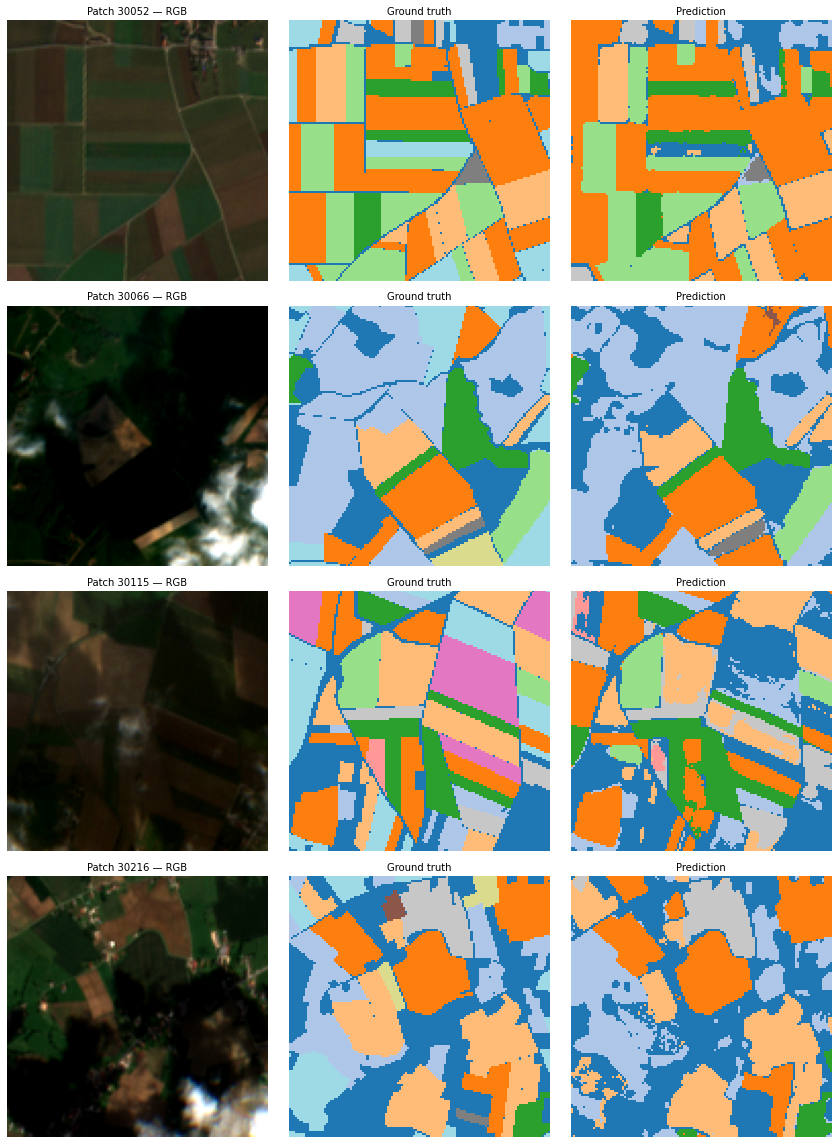

In [33]:
# --- Select a few test patches to visualise (RGB | ground truth | prediction) ---
show_test_ids = test_ids[:4]

fig, axes = plt.subplots(len(show_test_ids), 3, figsize=(12, 4 * len(show_test_ids)))

for row, pid in enumerate(show_test_ids):
    # --- RGB (clearest date) ---
    s2 = np.load(S2_DIR / f"S2_{pid}.npy").astype(np.float32) / 10000.0   # (T, C, H, W)
    t = int(np.argmin(s2[:, 0].mean(axis=(1, 2))))
    rgb = np.clip(s2[t, [2, 1, 0]].transpose(1, 2, 0) / 0.3, 0, 1)

    # --- Ground truth ---
    lab = np.load(ANN_DIR / f"TARGET_{pid}.npy")[0]   # (128, 128)

    # --- Prediction: pull this patch's rows from X (Task A pixel table), predict, reshape ---
    patch_mask = patch_of_pixel == pid
    X_patch = X[patch_mask]                       # (16384, 460)
    pred = rf.predict(X_patch).reshape(128, 128)   # back to (H, W)

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"Patch {pid} — RGB", fontsize=10)

    axes[row, 1].imshow(lab, cmap="tab20", vmin=0, vmax=19, interpolation="nearest")
    axes[row, 1].set_title("Ground truth", fontsize=10)

    axes[row, 2].imshow(pred, cmap="tab20", vmin=0, vmax=19, interpolation="nearest")
    axes[row, 2].set_title("Prediction", fontsize=10)

    for a in axes[row]:
        a.axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
# --- Save predicted label maps for every test patch (outputs/predictions/) ---
# One 128x128 uint8 array per patch, same class IDs as the annotations. Void pixels
# are predicted too (the model assigns them a real class), so compare against the
# ground truth with void masked out, as in Task E.
for pid in test_ids:
    pred_map = rf.predict(X[patch_of_pixel == pid]).reshape(128, 128).astype(np.uint8)
    np.save(PRED_DIR / f"PRED_{pid}.npy", pred_map)

print(f"Saved {len(test_ids)} predicted label maps to {PRED_DIR}")

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      |

Saved 18 predicted label maps to D:\Jobs\Agri-Assignment_01\Agri-Assignment_01\outputs\predictions


[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.2s finished


# Task G: Analysis and Interpretation

## Why this model was chosen

Random Forest was selected as a traditional ML baseline appropriate for the available compute (local CPU, no GPU). It needs no feature scaling, handles the 460-dimensional pixel-level feature space directly, and trains in about 36 minutes on ~988K samples (8 CPU cores) — practical for iteration. The assignment favours a simpler, well-explained model over a more complex one with limited justification, which this satisfies: a single, interpretable model with a documented, class-aware handling of imbalance (`class_weight="balanced"`).

## Strengths and limitations of the approach

**Strengths:** strong performance on the well-represented crop classes (see below), fast to train and reproduce, and the per-pixel time series (46 dates x 10 bands) lets the model use the full growing season rather than a single snapshot — useful given some patches are heavily cloud-affected on any single date.

**Limitations:** the model classifies each pixel independently, with no awareness of neighbouring pixels. This produces the blurred, noisy field boundaries seen in Task F, since a segmentation-aware model (e.g. U-Net) would enforce spatial coherence that a per-pixel Random Forest cannot. It also cannot learn from classes it rarely or never sees in training, discussed further below.

## Interpretation of the evaluation results

*The numbers in this paragraph refer to the fixed split (test = fold 5); the cross-validated results follow below.*

Overall accuracy (85.1% val, 83.8% test) is close between the two sets, indicating the model generalizes reasonably well to unseen patches rather than overfitting. However, accuracy alone is misleading here due to class imbalance: the macro-averaged metrics (mIoU 0.45 val, 0.43 test) are far lower, since they weight every class equally rather than by pixel count. Splitting classes by how many patches they appear in shows the real picture: classes present in 25+ patches reach a macro IoU of 0.64, while classes present in fewer than 25 patches average only 0.13. The model is genuinely strong where it has adequate data, and the low overall macro score reflects a data-availability problem, not a fundamental modelling failure.

**5-fold cross-validation.** Across the five rounds, test performance is 0.841 ± 0.019 accuracy, 0.801 ± 0.026 MCC, 0.481 ± 0.053 macro F1 and 0.424 ± 0.049 mIoU. The fold-5 result (0.839 / 0.798 / 0.487 / 0.435) sits almost exactly on the mean, so the fixed split was representative rather than lucky. Validation and test means are nearly identical, as expected since no tuning was done on validation. Accuracy and MCC vary little between folds, while the macro metrics vary more, from macro F1 0.39 (test fold 2) to 0.52 (test folds 3 and 4). This is because the rare classes present in each test fold differ, and each rare class counts as much as a major one in a macro average.

The pooled out-of-fold predictions cover all 1,527,081 non-void pixels and all 18 classes, compared with 15 in the fold-5 test set. They confirm the class-support pattern: well-represented classes reach macro IoU 0.642 and F1 0.729, the same as on fold 5, while sparse classes fall to IoU 0.081 and F1 0.101. The sparse group is lower than on fold 5 (0.125) because it now includes Grapevine, Potatoes and Orchard, which cannot be predicted at all, since their only patch is in the test fold whenever they are evaluated. Sparse-class precision (0.21) is much higher than recall (0.09): the model rarely predicts these classes, and misses most of their pixels. The pooled all-class mIoU (0.362) is lower than the per-round mean (0.424) for the same reason: it averages over all 18 classes, including the three that are unlearnable.

## Classes that performed well or poorly

**Performed well:** Winter rapeseed (IoU 0.91-0.93), Corn (0.87-0.89), Soft winter wheat (0.83-0.88), Winter barley (0.86), Soybeans (0.83) — all well-represented classes with distinct spectral/temporal signatures.

**Performed poorly:** Spring barley, Winter durum wheat, Fruits/veg/flowers, Mixed cereal, Sorghum, and Leguminous fodder all scored at or near 0.00-0.10 IoU. Three classes — Grapevine, Potatoes, Orchard — could not be evaluated at all, since each occurred in only a single patch, which landed entirely in the training folds under the Task C split. The 5-fold rotating cross-validation in Task E does place each of these patches in a test fold once, but in that round the class has no training examples at all, so it cannot be predicted; these three classes need more data, not a different split.

## Possible reasons for confusion between specific crop classes

The confusion matrix showed two clear patterns: Winter triticale was frequently predicted as Soft winter wheat, both winter cereals with overlapping growth cycles and similar reflectance; and Leguminous fodder and Sorghum showed confusion with Meadow and Soybeans respectively, all broadleaf/green vegetative covers with less spectrally distinct signatures than the dominant cereal and oilseed classes.

## Effects of class imbalance, limited samples, or label quality

Class imbalance is severe: Background and three crop classes make up over 70% of all labelled pixels, while several classes fall below 0.1% each. `class_weight="balanced"` reweights the training loss but cannot substitute for missing spectral variation — a class seen in only 1-3 patches has almost no diversity in growing conditions, field size, or timing for the model to learn from. This, not the modelling approach, is the primary driver of the poor sparse-class results.

## Effects of spatial resolution, cloud contamination, missing observations, or seasonal timing

**Spatial resolution:** all 10 bands share a common 128x128 grid despite being natively 10 m (B2, B3, B4, B8) or 20 m (B5, B6, B7, B8A, B11, B12) resolution, so the 20 m bands likely carry resampled, less spatially precise detail than their grid size suggests.

**Cloud contamination:** the per-date check in B.10 flags pixels with blue reflectance > 0.2 as cloud-like; its output shows how many of the 46 dates are substantially affected, both over the whole AOI and per patch. All 46 dates were kept as-is (no cloud masking or compositing); this adds noise to the feature vector but the monthly/seasonal signal from the remaining clear dates still carries useful information, as Task F's cloudy-patch example showed.

**Missing observations:** not applicable here — all 102 patches share exactly the same 46 acquisition dates, so no patch has fewer observations than another.

**Seasonal timing:** the date range (Sept 2018 to Oct 2019) spans one full agricultural year, aligning with the crop calendar inferred below.

## Useful information or assumptions about the AOI

The 102 patches sit within a single Sentinel-2 tile, centred around approximately 46.77°N, 5.16°E — placing the AOI in eastern France (Jura / Saône-et-Loire area), based on the metadata's declared CRS (EPSG:2154) and coordinate conversion; **this location was independently verified on Google Earth**. The one-year observation window and the mix of winter cereals (wheat, barley, rapeseed — sown autumn, harvested summer) alongside summer crops (corn, soybeans, sorghum — sown spring, harvested autumn) are consistent with a temperate European crop rotation calendar, though this interpretation was not checked against external agricultural records.

## Recommended next steps for improving the model or dataset

- Re-run the split with a stratification check to ensure every class appears in at least train and test (the current fold-based split left 3 classes entirely unevaluable).
- The rotating 5-fold cross-validation (Task E) already addresses the single-split problem for evaluation. A natural extension is to use it for model selection too, e.g. tuning `max_depth` / `min_samples_leaf` on each round's validation fold.
- A cloud mask or per-date quality flag, if available, would let cloudy observations be down-weighted or excluded, rather than treated as valid reflectance.
- A spatially-aware model (U-Net, or the same Random Forest with added neighbourhood/texture features) would likely reduce the boundary noise seen in Task F.
- More patches — or targeted new data — for the classes with fewer than 10 total patches would do more to raise the macro-average score than any modelling change.